# Using _EGObox_ surrogate model _Gpx_

_Last update: 17/03/2026_

## Installation

In [1]:
# %pip install egobox

We import _egobox_ as _egx_ for short

In [2]:
import egobox as egx

# Example 1 : Gpx basics

### Training 

#### Training data definition

In [3]:
import numpy as np

xt = np.array([0.0, 1.0, 2.0, 3.0, 4.0]).T
yt = np.array([0.0, 1.0, 1.5, 0.9, 1.0])

#### Building the surrogate

In [4]:
gpx = egx.Gpx.builder().fit(xt, yt)

### Prediction

#### Using the surrogate for estimation

In [5]:
# number of x locations to estimate
num = 100

# x should have 2D shape (nsamples, nx)
x = np.linspace(0.0, 4.0, num).reshape((-1, 1))

# estimated values
y = gpx.predict(x)
# estimated variances
s2 = gpx.predict_var(x)

# Print hyperparameters
print(f"Optimal theta = {gpx.thetas[0]}")
print(f"GP variance = {gpx.variances[0]}")
print(f"Reduced likelihood = {gpx.likelihoods[0]}")

Optimal theta = [1.83209681]
GP variance = 0.3049400993758991
Reduced likelihood = 0.5781740714710881


#### Plotting results

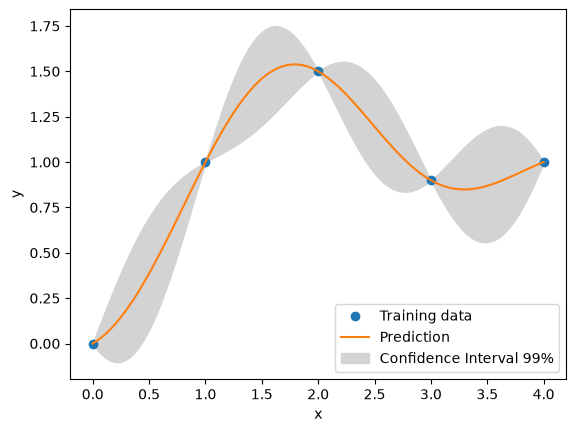

In [6]:
import matplotlib.pyplot as plt

def plot_gp(xt, yt, x, y, s2):
    fig, axs = plt.subplots(1)
    
    # training data
    axs.plot(xt, yt, "o")
    
    # gp mean
    axs.plot(x, y)
    
    # 99% confidence interval
    axs.fill_between(
        np.ravel(x),
        np.ravel(y - 3 * np.sqrt(s2)),
        np.ravel(y + 3 * np.sqrt(s2)),
        color="lightgrey",
    )
    
    # legend
    axs.set_xlabel("x")
    axs.set_ylabel("y")
    axs.legend(
        ["Training data", "Prediction", "Confidence Interval 99%"],
        loc="lower right",
    )
    return axs

plot_gp(xt, yt, x, y, s2)
plt.show()

### Sampling

#### Sampling the conditionned Gaussian process

In [7]:
# number fo trajectories to sample
n_traj = 30

trajs = gpx.sample(x, n_traj)

#### Plotting trajectories

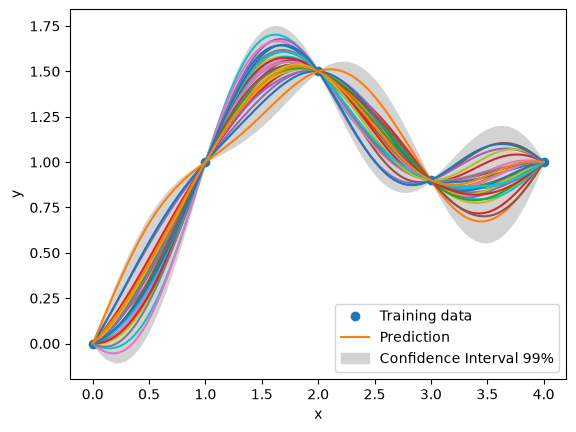

In [8]:
axs = plot_gp(xt, yt, x, y, s2)

for i in range(n_traj):
    axs.plot(x, trajs[:, i])

plt.show()

## Example 2 : Gpx trend and correlation models customization, saving and loading

### Test function

$$f : \left\{ \begin{array}{c} [-10, 10] \rightarrow \mathbb{R} \\ x \mapsto x^2 \sin(x) \ \end{array} \right.$$

In [9]:
import numpy as np

def f(x):
    return x**2 * np.sin(x)

### Training

$f$ is approximated with _Gpx_ at points $-8.5$,  $-4.0$,  $-3.0$,  $-1.0$, $4.0$ and  $7.5$. 

In [10]:
xt = np.array([[-8.5, -4.0, -3.0, -1.0, 4.0, 7.5]]).T
yt = f(xt)

To show features of _Gpx_, below, we build the surrogate asking for best GP regression by testing constant, linear or quadratic trend with either squared_exponential or matern52. The quality of the surrogate is assessed by cross validation.

In [11]:
gpx_builder = egx.Gpx.builder(regr_spec=egx.RegressionSpec.ALL, 
                              corr_spec=egx.CorrelationSpec.SQUARED_EXPONENTIAL | egx.CorrelationSpec.MATERN52)
gpx = gpx_builder.fit(xt, yt)

We can get string representations of the trained GP

In [12]:
print(f"Gpx string: {gpx}")
print(f"Gpx stringified JSON serialization {repr(gpx)}")

Gpx string: Mixture[Hard](Linear_Matern52GP(mean=LinearMean, corr=Matern52, theta=[5.032489555504639], variance=436.9630292354542, likelihood=3.0156045840852284))
Gpx stringified JSON serialization {"moe":{"recombination":"Hard","experts":[{"type_fullgp":"GpLinearMatern52Surrogate","theta":{"v":1,"dim":[1],"data":[5.032489555504639]},"likelihood":3.0156045840852284,"inner_params":{"sigma2":436.9630292354542,"beta":{"v":1,"dim":[2,1],"data":[-0.08079777271615114,0.8013251316204962]},"gamma":{"v":1,"dim":[6,1],"data":[-0.439287354978644,1.0536393682111043,-0.27558418335561424,0.11574703830956619,-0.9081345586190727,0.45361969043266065]},"r_chol":{"v":1,"dim":[6,6],"data":[1.000000000000011,0.0,0.0,0.0,0.0,0.0,0.005457121516095397,0.9999851098015313,0.0,0.0,0.0,0.0,0.001095692356133888,0.5997637402581525,0.8001763901352216,0.0,0.0,0.0,0.00003842742109284557,0.05246195420016222,0.21255611350498727,0.9757395351714055,0.0,0.0,5.728668017727316e-9,0.00001628709774458805,0.00010027971806564252

... and save it in a json file (for a human readable format) or in binary file (for optimizing performances).

In [13]:
gpx.save("gp.json")  # json extension is automatically detected hence json file format
gpx.save("gp.bin")   # otherwise binary (you can compare here the size on disk)

True

We can reload it with

In [14]:
gpx = egx.Gpx.load("gp.json")

### Prediction

In [15]:
x_min, x_max = -10, 10
n_plot = 500

# x must have (nsamples, nx) shape
x = np.linspace(x_min, x_max, n_plot).reshape(-1, 1)

y = gpx.predict(x)
s2 = gpx.predict_var(x)

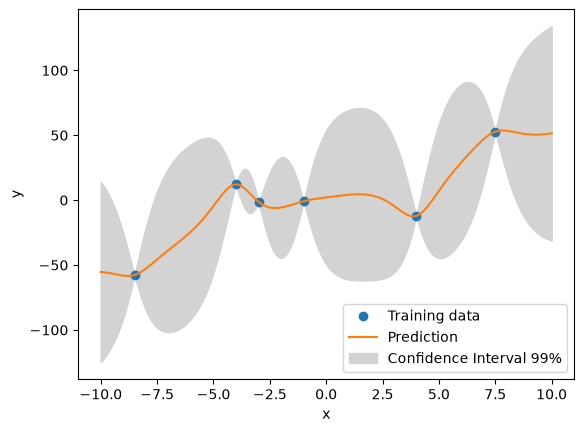

In [16]:
plot_gp(xt, yt, x, y, s2)
plt.show()

### Sampling

#### Sampling the conditionned Gaussian process

In [17]:
# number fo trajectories to sample
n_traj = 10

trajs = gpx.sample(x, n_traj)

#### Plotting trajectories

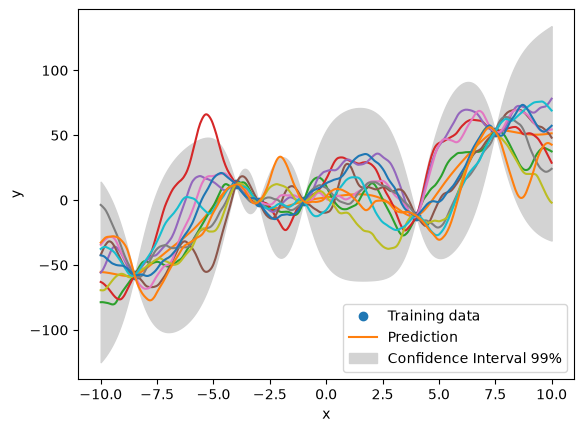

In [18]:
axs = plot_gp(xt, yt, x, y, s2)

for i in range(n_traj):
    axs.plot(x, trajs[:, i])

plt.show()

## Example 3 : Clustering

### Test function

We are going to use a test function with three modes to show clustering feature

In [19]:
def function_3modes(x):
    y = np.zeros(x.shape)
    y[x < 0.4] = x[x < 0.4] ** 2
    y[(x >= 0.4) & (x < 0.8)] = 3 * x[(x >= 0.4) & (x < 0.8)] + 1
    y[x >= 0.8] = np.sin(10 * x[x >= 0.8])
    return y

### Training 

#### Training data definition

In [20]:
np.random.seed(42)  # results may differ depending on training data, set seed here for reproducibility
xt = np.random.sample(60).reshape((-1, 1))
yt = function_3modes(xt)

#### Building the surrogate

In [21]:
gpx = egx.Gpx.builder(n_clusters=3).fit(xt, yt)

In [22]:
print(gpx)

Mixture[Hard](Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.24588196692555592], variance=1.0027864126664414, likelihood=89.03715261280115), Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.12661932675109444], variance=1.3915179355727303, likelihood=192.54862600735282), Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.23368100874673817], variance=0.027075515727448433, likelihood=278.2456521557965))


We see that 3 experts are smoothly recombined with an heasviside factor of 0.1 automatically adjusted to improve the overall surrogate quality.

### Plotting

In [23]:
x_min, x_max = 0, 1
n_plot = 500

# x must have (nsamples, nx) shape
x = np.linspace(x_min, x_max, n_plot).reshape(-1, 1)

y = gpx.predict(x)
s2 = gpx.predict_var(x)

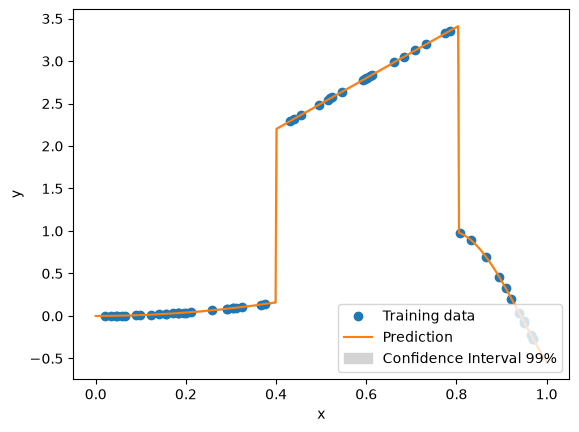

In [24]:
plot_gp(xt, yt, x, y, s2)
plt.show()

We can check it is better than one cluster (the default).

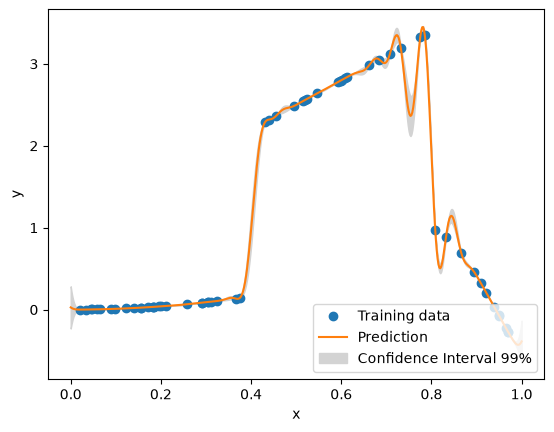

In [25]:
gpx = egx.Gpx.builder().fit(xt, yt)
y = gpx.predict(x)
s2 = gpx.predict_var(x)
plot_gp(xt, yt, x, y, s2)
plt.show()

We can also let _Gpx_ find the  best number of clusters

(60, 1)
Mixture[Hard](Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.24588196692555592], variance=1.0027864126664414, likelihood=89.03715261280115), Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.12661932675109444], variance=1.3915179355727303, likelihood=192.54862600735282), Constant_SquaredExponentialGP(mean=ConstantMean, corr=SquaredExponential, theta=[0.23368100874673817], variance=0.027075515727448433, likelihood=278.2456521557965))


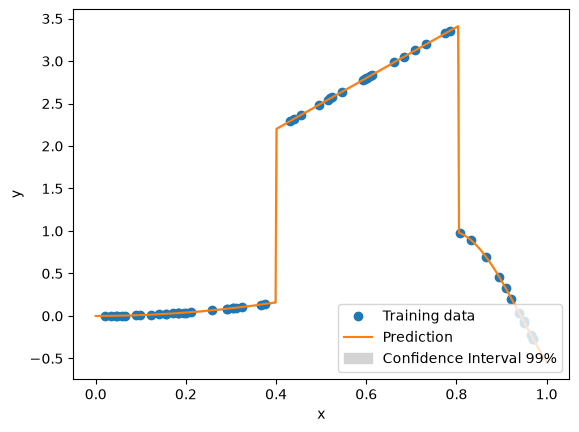

In [26]:
print(yt.shape)
gpx = egx.Gpx.builder(n_clusters=0).fit(xt, yt)
print(gpx)
y = gpx.predict(x)
s2 = gpx.predict_var(x)
plot_gp(xt, yt, x, y, s2)
plt.show()

## Example 4: _Gpx_ with discrete variables

_Gpx_ accepts discrete variables specified through `egx.XSpec` and `egx.XType` as stated below.

In [27]:
float_tol = 1e-7

def function_4d(x):
    return x[:, 0] + x[:, 1] + x[:, 2] + x[:, 3]

xspecs = [
    egx.XSpec(egx.XType.ORD, [1, 2, 3]),
    egx.XSpec(egx.XType.ENUM, tags=["blue", "red", "green"]),
    egx.XSpec(egx.XType.INT, [5.0, 10.0]),
    egx.XSpec(egx.XType.FLOAT, [0.0, float_tol]),
]
xt = egx.lhs(xspecs, 50)
yt = function_4d(xt)
gpx = egx.Gpx.builder(seed=42).fit(xt, yt)

# check interpolation
for i in range(xt.shape[0]):
    # print(f"xt[{i}, :] = {xt[i, :]} -> yt[{i}] = {yt[i]} vs gpx.predict(xt[{i}, :]) = {gpx.predict(np.atleast_2d(xt[i, :])).item()}")
    assert(
        yt[i] - gpx.predict(np.atleast_2d(xt[i, :])).item() < 10*float_tol
    )

xv = egx.lhs(xspecs, 5)
print("xv = " + str(xv))

yv = function_4d(xv)

yv_pred = gpx.predict(xv)
error = np.linalg.norm(yv_pred - yv) / np.linalg.norm(yv)
print("yv_pred = " + str(yv_pred))
print("yv = " + str(yv))


xv = [[1.00000000e+00 0.00000000e+00 1.00000000e+01 6.70439046e-08]
 [1.00000000e+00 2.00000000e+00 5.00000000e+00 5.39657939e-08]
 [2.00000000e+00 1.00000000e+00 6.00000000e+00 2.78334502e-08]
 [3.00000000e+00 0.00000000e+00 7.00000000e+00 1.60406691e-08]
 [3.00000000e+00 2.00000000e+00 8.00000000e+00 8.88688402e-08]]
yv_pred = [11.00000073  8.00000002  8.99999994  9.99999988 12.99999942]
yv = [11.00000007  8.00000005  9.00000003 10.00000002 13.00000009]


## Gpx API

In [28]:
help(egx.GpMix)

Help on class GpMix in module egobox:

class GpMix(builtins.object)
 |  GpMix(xspecs=None, regr_spec=Ellipsis, corr_spec=Ellipsis, kpls_dim=None, n_clusters=1, recombination=Ellipsis, theta_init=None, theta_bounds=None, theta_n_start=Ellipsis, theta_max_eval=Ellipsis, seed=None, verbose=None)
 |
 |  Gaussian processes mixture builder
 |
 |  Parameters
 |  ----------
 |  xspecs : list of XSpec, list of [lower, upper] or None
 |      Specifications of the nx components of the input x (eg. len(xspecs) == nx),
 |      with XSpec(xtype=FLOAT|INT|ORD|ENUM, xlimits=[<f(xtype)>] or tags=[strings]).
 |      Depending on the x type we get the following for xlimits:
 |
 |      * when FLOAT: xlimits is [float lower_bound, float upper_bound],
 |      * when INT: xlimits is [int lower_bound, int upper_bound],
 |      * when ORD: xlimits is [float_1, float_2, ..., float_n],
 |      * when ENUM: xlimits is just the int size of the enumeration otherwise a list of tags is specified
 |        (eg xlimits

In [29]:
help(egx.Gpx)

Help on class Gpx in module egobox:

class Gpx(builtins.object)
 |  A trained Gaussian processes mixture
 |
 |  Methods defined here:
 |
 |  __repr__(self, /)
 |      Return repr(self).
 |
 |  __str__(self, /)
 |      Return str(self).
 |
 |  dims(self, /)
 |      Get the input and output dimensions of the surrogate
 |
 |      Returns
 |      -------
 |      tuple[int, int]
 |          the couple (nx, ny)
 |
 |  predict(self, /, x, return_std=False)
 |      Predict output values at nsamples points.
 |
 |      Parameters
 |      ----------
 |      x : array[nsamples, nx] or array[nsamples] when nx == 1
 |          input values
 |      return_std : bool
 |          When True, the standard deviations of the predictions are also returned,
 |          computed as sqrt(predict_var(x)) (default is False)
 |
 |      Returns
 |      -------
 |      array[nsamples] or (array[nsamples], array[nsamples])
 |          the output values at the nsamples x points,
 |          and their standard deviati